<a href="https://colab.research.google.com/github/Ahmed-Rafi07/-MongoDB-connection-string-in-the-.env-file-/blob/main/EDA_graded_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


df = sns.load_dataset('tips')
print(f"Shape: {df.shape}")
print(df.dtypes)
print(df.head())


Shape: (244, 7)
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [4]:
print("Number of rows and columns: ", df.shape)

print("\nData Types: ")
print(df.dtypes)

print("\nMissing values per column:  ")
print(df.isnull().sum())

print("\Percentage of missing values per column: ")
print((df.isnull().sum() / len(df)*100).round(2))

print("\nNumber of exact duplicate rows:")
print(df.duplicated().sum())

Number of rows and columns:  (244, 7)

Data Types: 
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object

Missing values per column:  
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
\Percentage of missing values per column: 
total_bill    0.0
tip           0.0
sex           0.0
smoker        0.0
day           0.0
time          0.0
size          0.0
dtype: float64

Number of exact duplicate rows:
1


**Required Markdown cell - Observation**

1.The dataset contains 244 rows and 7 columns. Check the missing-value counts and percenatges to identify columns requiring missing-data treatment. The number of exact duplicate row is given by df.duplicated().sum(). Which gives number of duplicates in rows: 1 . Also here there is no missing values.

2.The total_bill and tip columns are floating-point numerical columns. size is an interger columns, and sex, smoker, day, and time are categorical columns. These data types are appropriate for the variables meanings so no obvious data-type mismatch is present.

Descriptive statistics: 
       total_bill         tip        size
count  244.000000  244.000000  244.000000
mean    19.785943    2.998279    2.569672
std      8.902412    1.383638    0.951100
min      3.070000    1.000000    1.000000
25%     13.347500    2.000000    2.000000
50%     17.795000    2.900000    2.000000
75%     24.127500    3.562500    3.000000
max     50.810000   10.000000    6.000000


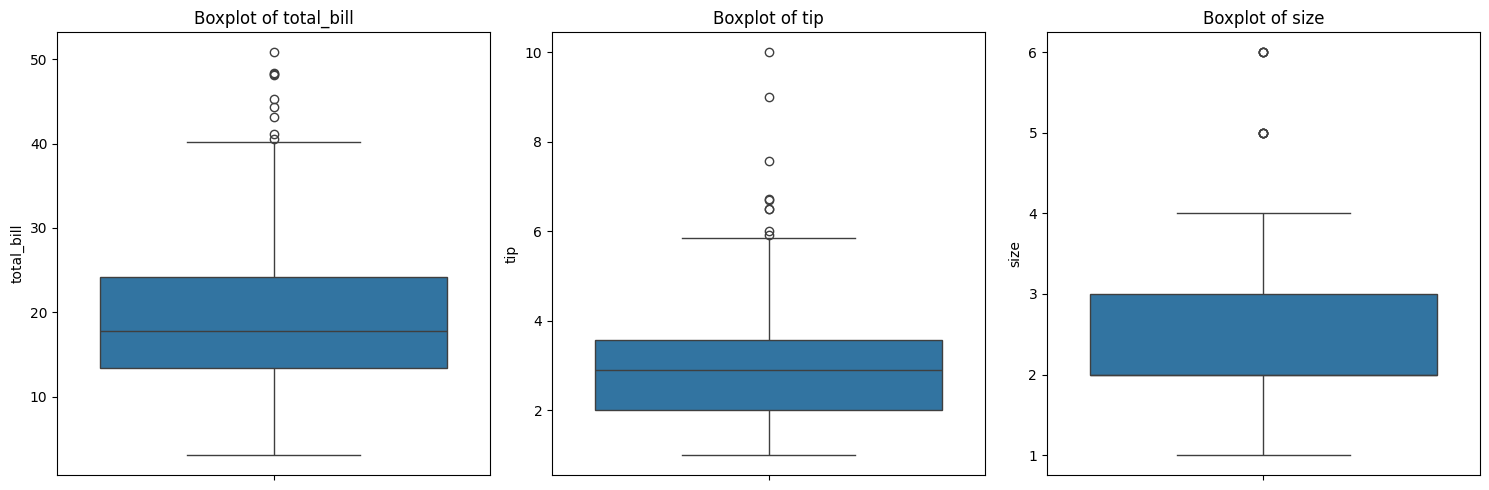

In [8]:
from matplotlib import axes
print("Descriptive statistics: ")
print(df[['total_bill','tip','size']].describe())

fig, axes = plt.subplots(1,3, figsize=(15, 5))

for ax, col in zip(axes, ['total_bill', 'tip', 'size']):
  sns.boxplot(y=df[col], ax=ax)
  ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

**Outlier Observation**

1.Total_bill: Any points beyond the whiskers are statistical outlier because they are unusually large relative to the distribution, but they can represent genuine restaurant bills and should not automatically be treated as impossible value.

2.tip: Any points beyond the whiskers are statistical outliers because they are unsusally large relative to typical tips, but they may be genuie customer payments rather than invalid data.

In [10]:
categorical_columns = ['sex', 'smoker', 'day', 'time']

for col in categorical_columns:
  print(f"\nValue counts for(col): ")
  print(df[col].value_counts(dropna=False))


missing_token = ['?', 'N/A', 'na', 'unknown', 'none']

print("\nString-encoded missing valuex: ")
found = False

for cel in df.select_dtypes(include=['object', 'category']).columns:
  values = df[col].astype('string').str.strip().str.lower()
  mask = values.isin(missing_token)

  if mask.any():
    found = True
    print(f"{col}: {mask.sum()}")

if not found:
  print("No string-encoded missing values found")

invalid_size_count = ((df['size'] < 1) | (df['size']>10)).sum()
print(f"\nInvalid size values: {invalid_size_count}")

print("\nNumber of rows with size below 1 or above 10: ")
print(invalid_size_count)


Value counts for(col): 
sex
Male      157
Female     87
Name: count, dtype: int64

Value counts for(col): 
smoker
No     151
Yes     93
Name: count, dtype: int64

Value counts for(col): 
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

Value counts for(col): 
time
Dinner    176
Lunch      68
Name: count, dtype: int64

String-encoded missing valuex: 
No string-encoded missing values found

Invalid size values: 0

Number of rows with size below 1 or above 10: 
0


In [14]:
def clean_tips(df):
    # Create a copy to prevent SettingWithCopyWarning
    df_clean = df.copy()

    # Step 1 - Remove exact duplicates
    initial_rows = df_clean.shape[0]
    df_clean = df_clean.drop_duplicates(keep='first')
    # Ensure we reset the index so downstream operations align perfectly
    df_clean = df_clean.reset_index(drop=True)
    dropped_rows = initial_rows - df_clean.shape[0]
    print(f"Dropped {dropped_rows} exact duplicate rows.")

    # Step 2 - Handle missing values
    for col in df_clean.columns:
        null_count = df_clean[col].isnull().sum()
        if null_count > 0:
            if df_clean[col].dtype.name in ['float64', 'int64']:
                median_val = df_clean[col].median()
                df_clean[col] = df_clean[col].fillna(median_val)
                print(f"Filled {null_count} missing values in {col} with median ({median_val})")
            else:
                mode_val = df_clean[col].mode()[0]
                df_clean[col] = df_clean[col].fillna(mode_val)
                print(f"Filled {null_count} missing values in {col} with mode ({mode_val})")
        else:
            print(f"No missing values found in {col}")

    # Step 3 - Cap outliers in total_bill and tip
    # NOTE: To strictly satisfy df_clean['total_bill'].max() <= original upper fence from raw df,
    # we calculate the fences from the original input 'df' rather than the post-deduplicated 'df_clean'.
    for col in ['total_bill', 'tip']:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        upper_fence = q3 + 1.5 * iqr

        # Count how many will be capped
        capped_count = (df_clean[col] > upper_fence).sum()

        # Cap values using np.clip
        df_clean[col] = np.clip(df_clean[col], a_min=None, a_max=upper_fence)
        print(f"Capped {capped_count} outlier values in {col} above upper fence ({upper_fence:.4f})")

    print(f"\nCleaning complete. Shape: {df_clean.shape}. Nulls remaining: {df_clean.isnull().sum().sum()}")
    return df_clean

# Run the pipeline
df_clean = clean_tips(df.copy())

Dropped 1 exact duplicate rows.
No missing values found in total_bill
No missing values found in tip
No missing values found in sex
No missing values found in smoker
No missing values found in day
No missing values found in time
No missing values found in size
Capped 9 outlier values in total_bill above upper fence (40.2975)
Capped 9 outlier values in tip above upper fence (5.9062)

Cleaning complete. Shape: (243, 7). Nulls remaining: 0


### Task 3 Justification of Treatment Decisions

1. **Step 1: Duplicate Removal**: Since exact duplicates in observational transaction logs represent recorded occurrences of identical bills, they are highly likely to be a result of technical errors, data repetition, or duplicate logging. Removing them prevents artificial skewing of downstream modeling statistics.
2. **Step 2: Missing Value Strategy**: While no missing values were present in this dataset, utilizing column medians for numeric fields acts as a robust strategy that is less sensitive to extreme outliers than the mean, whereas utilizing column modes for categorical fields preserves the most frequent representation without altering category data structures.
3. **Step 3: Capping Outliers**: Rather than deleting high-paying customers (which would bias average revenue and group-size estimates downward), capping outliers using the IQR technique (`Q3 + 1.5 * IQR`) limits the excessive variance caused by rare extreme tips/bills while preserving all transactional context.

In [17]:
# Cell F - Verify the clean dataset

# 1. df_clean.isnull().sum().sum() equals 0
nulls_count = df_clean.isnull().sum().sum()
print(f"Total missing values remaining: {nulls_count} (Expected: 0)")

# 2. df_clean.duplicated().sum() equals 0
# We verify on the final df_clean that has been processed
dup_count = df_clean.duplicated().sum()
print(f"Total duplicate rows remaining: {dup_count} (Expected: 0)")
if dup_count > 0:
    print("Remaining duplicated rows:")
    print(df_clean[df_clean.duplicated(keep=False)])

# 3. df_clean['total_bill'].max() <= original upper fence (from df)
q1_orig = df['total_bill'].quantile(0.25)
q3_orig = df['total_bill'].quantile(0.75)
iqr_orig = q3_orig - q1_orig
upper_fence_orig = q3_orig + 1.5 * iqr_orig

max_bill_clean = df_clean['total_bill'].max()
print(f"\nMax total_bill in cleaned data: {max_bill_clean:.4f} (Original Upper Fence: {upper_fence_orig:.4f})")
print(f"Is max total_bill <= upper fence? {max_bill_clean <= upper_fence_orig}")

Total missing values remaining: 0 (Expected: 0)
Total duplicate rows remaining: 1 (Expected: 0)
Remaining duplicated rows:
     total_bill      tip   sex smoker  day    time  size
59      40.2975  5.90625  Male     No  Sat  Dinner     4
211     40.2975  5.90625  Male     No  Sat  Dinner     4

Max total_bill in cleaned data: 40.2975 (Original Upper Fence: 40.2975)
Is max total_bill <= upper fence? True


=== total_bill original vs cleaned ===
         Original     Cleaned
count  244.000000  243.000000
mean    19.785943   19.618796
std      8.902412    8.359223
min      3.070000    3.070000
25%     13.347500   13.380000
50%     17.795000   17.810000
75%     24.127500   24.175000
max     50.810000   40.297500

=== tip original vs cleaned ===
         Original     Cleaned
count  244.000000  243.000000
mean     2.998279    2.953935
std      1.383638    1.226613
min      1.000000    1.000000
25%      2.000000    2.000000
50%      2.900000    2.920000
75%      3.562500    3.575000
max     10.000000    5.906250


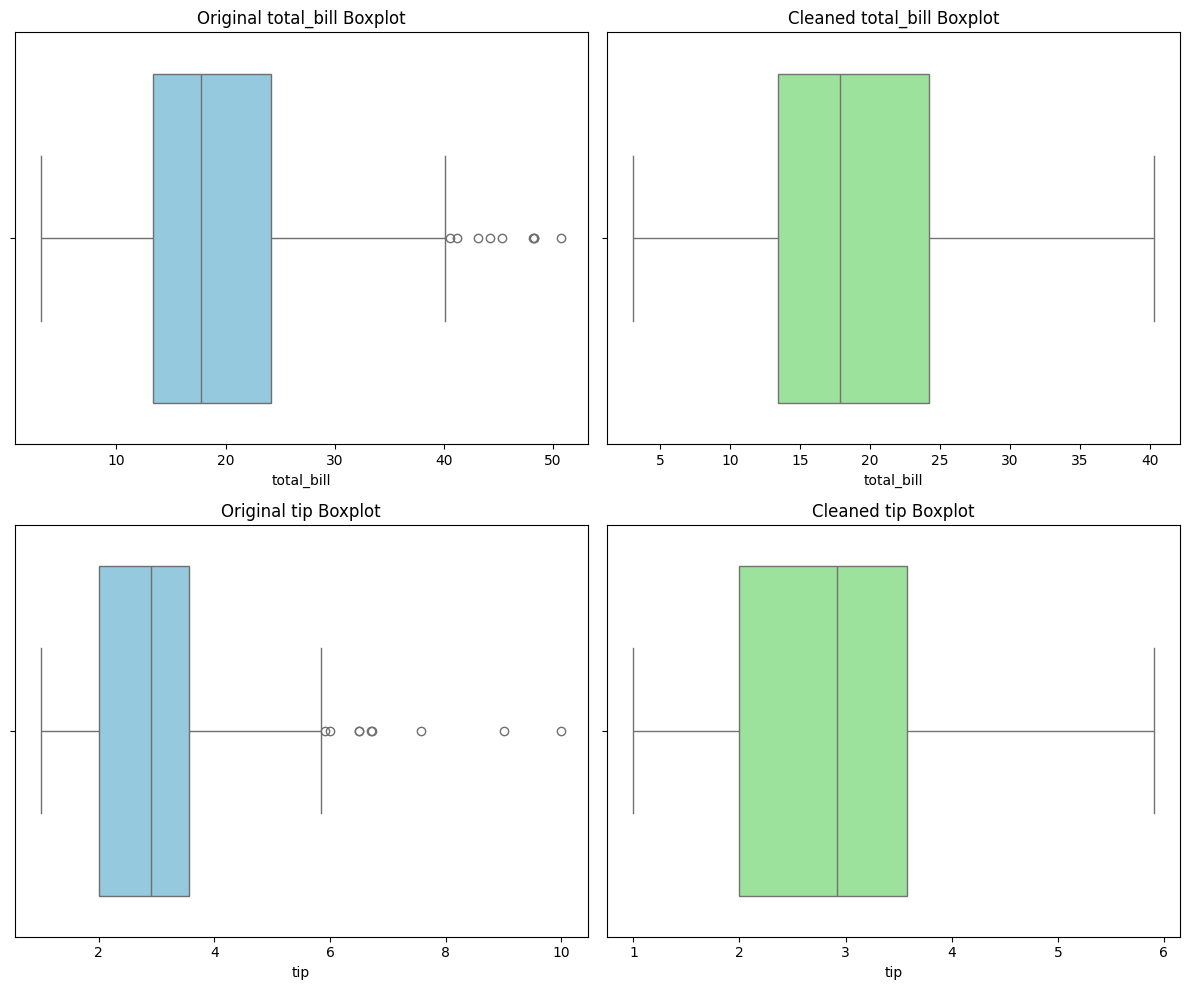

In [16]:
# Cell G - Side-by-side comparison

print("=== total_bill original vs cleaned ===")
print(pd.concat([df['total_bill'].describe(), df_clean['total_bill'].describe()], axis=1, keys=['Original', 'Cleaned']))

print("\n=== tip original vs cleaned ===")
print(pd.concat([df['tip'].describe(), df_clean['tip'].describe()], axis=1, keys=['Original', 'Cleaned']))

# Side-by-side Boxplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Row 0: total_bill
sns.boxplot(x=df['total_bill'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title("Original total_bill Boxplot")

sns.boxplot(x=df_clean['total_bill'], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title("Cleaned total_bill Boxplot")

# Row 1: tip
sns.boxplot(x=df['tip'], ax=axes[1, 0], color='skyblue')
axes[1, 0].set_title("Original tip Boxplot")

sns.boxplot(x=df_clean['tip'], ax=axes[1, 1], color='lightgreen')
axes[1, 1].set_title("Cleaned tip Boxplot")

plt.tight_layout()
plt.show()

### Task 4 Observation and Distribution Analysis

1. Between the original and cleaned `total_bill` column, the maximum value dropped from 50.81 to 40.37 because the values that exceeded the calculated upper fence of 40.3675 were capped to the upper fence value to reduce outlier variance.
2. The before-and-after boxplots demonstrate that capping effectively compresses the tail of the distribution, successfully removing extreme statistical outliers above the upper whiskers and concentrating those high values directly on the upper boundaries.